# Construção da base mensal para o projeto FTPL

Este notebook reproduz, em formato passo a passo, o pipeline de dados para o projeto:

**Debt Denomination, Fiscal Backing, and Inflation: Evidence from Brazilian Treasury Debt**

O objetivo é:

1. baixar os dados de leilões da DPMFi;
2. classificar os títulos em três grupos:
   - **N**: LTN e NTN-F;
   - **F**: LFT;
   - **R**: NTN-B;
3. construir a emissão bruta mensal por instrumento;
4. baixar e organizar o estoque da dívida por instrumento;
5. construir uma proxy predeterminada de vencimentos programados;
6. baixar variáveis macroeconômicas do BCB e do IBGE;
7. consolidar todas as séries em um painel mensal.

> **Observação importante:** este notebook precisa de acesso à internet para baixar os arquivos oficiais.


## 1. Instalação das dependências

Execute a célula abaixo apenas se os pacotes ainda não estiverem instalados no ambiente.

O pacote `xlrd` é necessário porque o histórico de leilões do Tesouro está em formato `.xls` antigo.


In [1]:
# Descomente a linha abaixo se necessário:
%pip install pandas numpy requests xlrd openpyxl urllib3

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

# Defina o diretório de saída dentro do seu Google Drive.
# Por favor, substitua 'SUA_PASTA_AQUI' pelo nome da sua pasta no Google Drive.
OUTPUT_DIR = Path("/content/drive/MyDrive/UDESC/Projetos/FTPL/data/")


## 2. Importações e configuração geral

Nesta etapa:

- importamos os pacotes;
- definimos as URLs oficiais;
- registramos os códigos das séries do BCB;
- criamos o mapeamento dos títulos para os grupos teóricos do artigo.


In [4]:
from __future__ import annotations

import logging
import re
import time
import unicodedata
from dataclasses import dataclass
from datetime import date
from pathlib import Path
from typing import Iterable

import numpy as np
import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")


In [5]:
AUCTIONS_URL = (
    "https://sisweb.tesouro.gov.br/apex/cosis/rleiloes/arquivos/todos/desc/"
    "historico-leiloes-todos.xls"
)
STOCK_URL = (
    "https://www.tesourotransparente.gov.br/ckan/dataset/"
    "0998f610-bc25-4ce3-b32c-a873447500c2/resource/"
    "b6280ed3-ef7e-4569-954a-bded97c2c8a1/download/estoquedpf.csv"
)
IBGE_IPCA_URL = "https://apisidra.ibge.gov.br/values/t/1737/n1/all/v/2266/p/all"
BCB_SGS_BASE = "https://api.bcb.gov.br/dados/serie/bcdata.sgs.{code}/dados"

# Official series used in the project documentation.
BCB_SERIES = {
    "selic_target_pa": 432,       # Meta Selic, % a.a., daily
    "ibc_br_sa": 24364,           # IBC-Br seasonally adjusted, monthly (24363 is the NSA series; fixed 2026-11-22)
    "brl_usd": 3698,              # BRL/USD monthly series
}

INSTRUMENT_MAP = {
    "LTN": "N",
    "NTN-F": "N",
    "LFT": "F",
    "NTN-B": "R",
}

SALE_OPERATIONS = {"VENDA", "EXTRA VENDA"}




## 3. Estrutura de pastas e funções auxiliares

O pipeline separa os arquivos em:

- `data/raw/`: arquivos originais baixados das fontes oficiais;
- `data/clean/`: bases tratadas e consolidadas.

Também criamos:

- uma sessão HTTP com tentativas automáticas em caso de falha;
- funções para remover acentos e padronizar nomes de colunas;
- uma função genérica de download.


In [6]:
@dataclass(frozen=True)
class Paths:
    root: Path
    raw: Path
    clean: Path

    @classmethod
    def create(cls, root: Path) -> "Paths":
        raw = root / "raw"
        clean = root / "clean"
        raw.mkdir(parents=True, exist_ok=True)
        clean.mkdir(parents=True, exist_ok=True)
        return cls(root=root, raw=raw, clean=clean)


def build_session() -> requests.Session:
    retry = Retry(
        total=5,
        connect=5,
        read=5,
        status=5,
        backoff_factor=1.0,
        status_forcelist=(429, 500, 502, 503, 504),
        allowed_methods=("GET",),
    )
    session = requests.Session()
    session.headers.update({"User-Agent": "FTPL-research-data/1.0"})
    session.mount("https://", HTTPAdapter(max_retries=retry))
    return session


def download_file(session: requests.Session, url: str, destination: Path) -> Path:
    logging.info("Downloading %s", url)
    with session.get(url, timeout=120, stream=True) as response:
        response.raise_for_status()
        tmp = destination.with_suffix(destination.suffix + ".part")
        with tmp.open("wb") as handle:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    handle.write(chunk)
        tmp.replace(destination)
    return destination


def strip_accents(value: object) -> str:
    text = "" if pd.isna(value) else str(value)
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", text).strip()


def normalize_col(value: object) -> str:
    text = strip_accents(value).lower()
    text = re.sub(r"[^a-z0-9]+", "_", text).strip("_")
    return text


def find_col(columns: Iterable[str], required_tokens: Iterable[str]) -> str:
    required = tuple(required_tokens)
    matches = [c for c in columns if all(token in c for token in required)]
    if not matches:
        raise KeyError(f"No column contains all tokens {required}. Available: {list(columns)}")
    return matches[0]




## 4. Leitura e limpeza do histórico de leilões

O arquivo oficial contém:

- uma aba por ano;
- cabeçalho na sexta linha;
- uma linha duplicada de cabeçalho em inglês;
- diferentes tipos de operação.

A função abaixo:

1. padroniza as colunas;
2. identifica título, tipo de leilão, liquidação, vencimento e valor financeiro;
3. remove a linha duplicada em inglês;
4. converte datas e valores.


In [7]:
def parse_auction_sheet(path: Path, sheet_name: str) -> pd.DataFrame:
    # Row 6 in Excel is the Portuguese header (zero-based header=5).
    df = pd.read_excel(path, sheet_name=sheet_name, header=5, engine="xlrd")
    df.columns = [normalize_col(c) for c in df.columns]
    df = df.dropna(axis=1, how="all")

    # Remove the duplicate English header row embedded as the first data row.
    title_col = find_col(df.columns, ("titulo",))
    df = df[df[title_col].astype(str).str.upper().ne("BOND TYPE")].copy()

    auction_date_col = find_col(df.columns, ("data", "leilao"))
    settlement_col = find_col(df.columns, ("data", "liquidacao"))
    maturity_col = find_col(df.columns, ("data", "vencimento"))
    operation_col = find_col(df.columns, ("tipo", "leilao"))
    amount_col = find_col(df.columns, ("financeiro", "r"))

    rename = {
        auction_date_col: "auction_date",
        title_col: "instrument",
        operation_col: "operation",
        settlement_col: "settlement_date",
        maturity_col: "maturity_date",
        amount_col: "accepted_amount_brl",
    }
    df = df.rename(columns=rename)

    keep = list(rename.values())
    if "volta" in df.columns:
        keep.append("volta")
    if "venda" in df.columns:
        keep.append("venda")
    df = df[[c for c in keep if c in df.columns]].copy()

    for col in ("auction_date", "settlement_date", "maturity_date"):
        df[col] = pd.to_datetime(df[col], errors="coerce")
    df["accepted_amount_brl"] = pd.to_numeric(df["accepted_amount_brl"], errors="coerce")
    df["instrument"] = df["instrument"].map(strip_accents).str.upper()
    df["operation"] = df["operation"].map(strip_accents).str.upper()
    df["sheet"] = sheet_name

    return df.dropna(subset=["instrument", "operation", "settlement_date"])




## 5. Construção da emissão bruta mensal

A emissão bruta é construída a partir do valor financeiro aceito nos leilões de:

- `Venda`;
- `Extra Venda`.

A agregação usa a **data de liquidação**, pois é nesse momento que o fluxo financeiro ocorre.

A classificação é:

$
N = \{LTN, NTN-F\}, \qquad
F = \{LFT\}, \qquad
R = \{NTN-B\}.
$

A medida mensal é:

$
G_t^j
=
\sum_{\ell \in t}
\mathbf{1}\{	ext{grupo}(\ell)=j\}
\mathbf{1}\{	ext{operação}(\ell)\in	ext{vendas}\}
\operatorname{Financeiro}_{\ell}.
$


In [8]:
def build_gross_issuance(auction_path: Path, clean_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    logging.info("Parsing auction workbook")
    workbook = pd.ExcelFile(auction_path, engine="xlrd")
    frames = []
    for sheet in workbook.sheet_names:
        if re.fullmatch(r"Ano \d{4}", str(sheet)):
            frames.append(parse_auction_sheet(auction_path, sheet))
    auctions = pd.concat(frames, ignore_index=True)

    auctions["debt_group"] = auctions["instrument"].map(INSTRUMENT_MAP)
    auctions["month"] = auctions["settlement_date"].dt.to_period("M").dt.to_timestamp()
    auctions["is_market_sale"] = auctions["operation"].isin(SALE_OPERATIONS)

    # Baseline: market sale amounts only. The workbook's Financeiro (R$) field is
    # separate from Financeiro para Bacen (R$), so direct BCB allotments are excluded.
    baseline = auctions[
        auctions["debt_group"].notna()
        & auctions["is_market_sale"]
        & auctions["accepted_amount_brl"].fillna(0).gt(0)
    ].copy()

    long = (
        baseline.groupby(["month", "debt_group"], as_index=False)
        .agg(
            gross_issuance_brl=("accepted_amount_brl", "sum"),
            n_auction_rows=("accepted_amount_brl", "size"),
            n_instruments=("instrument", "nunique"),
        )
        .sort_values(["month", "debt_group"])
    )

    wide = long.pivot(index="month", columns="debt_group", values="gross_issuance_brl")
    wide = wide.rename(columns={"N": "gross_N_brl", "F": "gross_F_brl", "R": "gross_R_brl"})
    wide = wide.reindex(columns=["gross_N_brl", "gross_F_brl", "gross_R_brl"]).fillna(0)
    wide["gross_total_NFR_brl"] = wide.sum(axis=1)
    wide = wide.reset_index().sort_values("month")

    auctions.to_csv(clean_dir / "auction_operations_clean.csv", index=False)
    long.to_csv(clean_dir / "gross_issuance_long.csv", index=False)
    wide.to_csv(clean_dir / "gross_issuance_wide.csv", index=False)
    return long, wide




## 6. Download das séries macroeconômicas

O notebook baixa:

- meta SELIC;
- IBC-Br dessazonalizado;
- câmbio BRL/USD;
- índice do IPCA.

As consultas ao SGS do BCB são feitas em blocos de até nove anos, porque consultas muito longas podem falhar.


In [9]:
from io import StringIO
from datetime import date
import time

import pandas as pd
import requests


def fetch_bcb_sgs(
    session: requests.Session,
    code: int,
    name: str,
    start: date = date(2000, 1, 1),
    end: date | None = None,
    chunk_years: int = 5,
    max_attempts: int = 5,
) -> pd.DataFrame:
    """
    Baixa uma série do SGS/BCB em blocos de tempo.

    A função tenta obter JSON e, caso o BCB devolva conteúdo não JSON,
    tenta novamente usando CSV.

    Parameters
    ----------
    session
        Sessão requests configurada.
    code
        Código SGS da série.
    name
        Nome da coluna no DataFrame final.
    start, end
        Datas inicial e final.
    chunk_years
        Tamanho máximo de cada consulta em anos.
    max_attempts
        Número de tentativas por intervalo.
    """

    end = end or date.today()

    frames: list[pd.DataFrame] = []
    chunk_start = pd.Timestamp(start)
    final_date = pd.Timestamp(end)

    base_url = (
        f"https://api.bcb.gov.br/dados/serie/"
        f"bcdata.sgs.{code}/dados"
    )

    headers = {
        "User-Agent": (
            "Mozilla/5.0 "
            "(X11; Linux x86_64) "
            "AppleWebKit/537.36 "
            "Chrome/124.0 Safari/537.36"
        ),
        "Accept": "application/json,text/csv,*/*",
    }

    while chunk_start <= final_date:

        chunk_end = min(
            chunk_start + pd.DateOffset(years=chunk_years, days=-1),
            final_date,
        )

        params_base = {
            "dataInicial": chunk_start.strftime("%d/%m/%Y"),
            "dataFinal": chunk_end.strftime("%d/%m/%Y"),
        }

        interval_ok = False
        last_error = None

        for attempt in range(1, max_attempts + 1):

            # ---------------------------------------------------------
            # Primeira tentativa: JSON
            # ---------------------------------------------------------
            try:
                params_json = {
                    **params_base,
                    "formato": "json",
                }

                response = session.get(
                    base_url,
                    params=params_json,
                    headers=headers,
                    timeout=90,
                )

                response.raise_for_status()

                content_type = response.headers.get(
                    "Content-Type", ""
                ).lower()

                text_start = response.text[:200].strip()

                if (
                    "json" not in content_type
                    and not text_start.startswith("[")
                    and not text_start.startswith("{")
                ):
                    raise ValueError(
                        "Resposta não parece ser JSON. "
                        f"Content-Type={content_type}; "
                        f"início={text_start!r}"
                    )

                payload = response.json()

                if isinstance(payload, list) and payload:
                    temp = pd.DataFrame(payload)

                    if {"data", "valor"}.issubset(temp.columns):
                        frames.append(temp)
                        interval_ok = True
                        break

                elif payload == []:
                    interval_ok = True
                    break

                else:
                    raise ValueError(
                        f"Estrutura JSON inesperada: {type(payload)}"
                    )

            except Exception as exc:
                last_error = exc

            # ---------------------------------------------------------
            # Segunda tentativa: CSV
            # ---------------------------------------------------------
            try:
                params_csv = {
                    **params_base,
                    "formato": "csv",
                }

                response = session.get(
                    base_url,
                    params=params_csv,
                    headers=headers,
                    timeout=90,
                )

                response.raise_for_status()

                text = response.text.strip()

                if not text:
                    raise ValueError("Resposta CSV vazia.")

                # O SGS normalmente usa separador ';'
                temp = pd.read_csv(
                    StringIO(text),
                    sep=";",
                    dtype=str,
                )

                temp.columns = [
                    str(col).strip().lower()
                    for col in temp.columns
                ]

                # Proteção contra possíveis variações de nomenclatura
                rename_map = {}

                if "data" not in temp.columns:
                    for col in temp.columns:
                        if "data" in col:
                            rename_map[col] = "data"
                            break

                if "valor" not in temp.columns:
                    for col in temp.columns:
                        if "valor" in col:
                            rename_map[col] = "valor"
                            break

                temp = temp.rename(columns=rename_map)

                if {"data", "valor"}.issubset(temp.columns):
                    frames.append(temp[["data", "valor"]])
                    interval_ok = True
                    break

                raise ValueError(
                    "CSV não contém as colunas data e valor. "
                    f"Colunas recebidas: {temp.columns.tolist()}"
                )

            except Exception as exc:
                last_error = exc

            wait_seconds = min(2 ** attempt, 30)

            print(
                f"Tentativa {attempt}/{max_attempts} falhou "
                f"para SGS {code}, intervalo "
                f"{chunk_start:%d/%m/%Y}–{chunk_end:%d/%m/%Y}. "
                f"Nova tentativa em {wait_seconds}s."
            )

            time.sleep(wait_seconds)

        if not interval_ok:
            raise RuntimeError(
                f"Não foi possível baixar a série SGS {code} "
                f"no intervalo "
                f"{chunk_start:%d/%m/%Y}–{chunk_end:%d/%m/%Y}. "
                f"Último erro: {last_error}"
            )

        chunk_start = chunk_end + pd.Timedelta(days=1)

        # Pequena pausa entre blocos para não sobrecarregar a API
        time.sleep(0.5)

    if not frames:
        return pd.DataFrame(columns=["date", name])

    df = pd.concat(frames, ignore_index=True)

    df["date"] = pd.to_datetime(
        df["data"],
        format="%d/%m/%Y",
        errors="coerce",
    )

    # The JSON API returns "638091.1" (dot = decimal separator); the CSV
    # fallback returns Brazilian format "638.091,1" or "638091,1". Only strings
    # containing a comma are Brazilian-formatted. (Bug fixed 2026-11-22: all dots
    # used to be removed, inflating JSON values by 10^decimals.)
    valor = df["valor"].astype(str).str.strip()
    is_br = valor.str.contains(",", regex=False)
    valor = valor.where(
        ~is_br,
        valor.str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
    )
    df[name] = pd.to_numeric(valor, errors="coerce")

    df = (
        df[["date", name]]
        .dropna(subset=["date", name])
        .drop_duplicates(subset="date", keep="last")
        .sort_values("date")
        .reset_index(drop=True)
    )

    return df


def monthly_from_bcb(df: pd.DataFrame, value_col: str, aggregation: str) -> pd.DataFrame:
    x = df.copy()
    x["month"] = x["date"].dt.to_period("M").dt.to_timestamp()
    if aggregation == "last":
        out = x.sort_values("date").groupby("month", as_index=False).last()
    elif aggregation == "mean":
        out = x.groupby("month", as_index=False)[value_col].mean()
    else:
        raise ValueError("aggregation must be 'last' or 'mean'")
    return out[["month", value_col]]


def fetch_ipca_ibge(session: requests.Session) -> pd.DataFrame:
    response = session.get(IBGE_IPCA_URL, timeout=120)
    response.raise_for_status()
    payload = response.json()
    if len(payload) < 2:
        raise RuntimeError("IBGE SIDRA returned no IPCA observations")

    df = pd.DataFrame(payload[1:])
    # D3C is the YYYYMM period code and V is the index value in this endpoint.
    if "D3C" not in df.columns or "V" not in df.columns:
        raise KeyError(f"Unexpected SIDRA schema: {df.columns.tolist()}")
    df["month"] = pd.to_datetime(df["D3C"].astype(str), format="%Y%m", errors="coerce")
    df["ipca_index"] = pd.to_numeric(df["V"].astype(str).str.replace(",", ".", regex=False), errors="coerce")
    df = df[["month", "ipca_index"]].dropna().drop_duplicates("month").sort_values("month")
    df["ipca_mom_pct"] = 100 * df["ipca_index"].pct_change()
    df["ipca_yoy_pct"] = 100 * (df["ipca_index"] / df["ipca_index"].shift(12) - 1)
    return df


def build_macro_panel(session: requests.Session, clean_dir: Path) -> pd.DataFrame:
    logging.info("Downloading BCB and IBGE macro series")
    selic_daily = fetch_bcb_sgs(session, BCB_SERIES["selic_target_pa"], "selic_target_pa")
    ibc = fetch_bcb_sgs(session, BCB_SERIES["ibc_br_sa"], "ibc_br_sa")
    fx = fetch_bcb_sgs(session, BCB_SERIES["brl_usd"], "brl_usd")

    selic_m = monthly_from_bcb(selic_daily, "selic_target_pa", "last")
    ibc_m = monthly_from_bcb(ibc, "ibc_br_sa", "last")
    fx_m = monthly_from_bcb(fx, "brl_usd", "mean")
    ipca = fetch_ipca_ibge(session)

    macro = selic_m.merge(ibc_m, on="month", how="outer")
    macro = macro.merge(fx_m, on="month", how="outer")
    macro = macro.merge(ipca, on="month", how="outer").sort_values("month")
    macro["ibc_br_mom_pct"] = 100 * macro["ibc_br_sa"].pct_change()
    macro["brl_usd_mom_pct"] = 100 * macro["brl_usd"].pct_change()
    macro.to_csv(clean_dir / "macro_monthly.csv", index=False)
    return macro




## 7. Estoque por instrumento e proxy de vencimentos programados

O arquivo `estoquedpf.csv` contém observações por:

- instrumento;
- vencimento;
- mês de referência;
- classe de carteira.

O estoque é agregado nos três grupos teóricos.

A proxy de vencimentos é construída como:

$
\widetilde M_{t\mid t-1}^{j}
=
\sum_{\substack{b\in j\
\operatorname{vencimento}(b)\in t}}
\operatorname{Estoque}_{b,t-1}.
$

Assim, o valor usado para prever a emissão em \(t\) foi observado em \(t-1\), preservando a predeterminação.

> Essa medida é uma proxy a valor de curva. Ela não inclui perfeitamente todos os cupons nem a atualização intramensal por SELIC ou IPCA.


In [10]:
def read_stock_file(stock_path: Path) -> pd.DataFrame:
    df = pd.read_csv(stock_path, sep=";", decimal=",", encoding="utf-8", low_memory=False)
    rename = {
        "Titulo/Contrato": "security",
        "Vencimento do Titulo/Contrato": "maturity_date",
        "Valor do Estoque": "stock_value_brl",
        "Quantidade do Estoque": "stock_quantity",
        "Mes do Estoque": "reference_month_raw",
        "Classe da Carteira": "portfolio_class",
        "Tipo de Divida": "debt_type",
    }
    missing = set(rename) - set(df.columns)
    if missing:
        raise KeyError(f"Missing stock columns: {sorted(missing)}")
    df = df.rename(columns=rename)
    df["security_family"] = (
        df["security"].map(strip_accents).str.upper().str.extract(r"^(NTN-B|NTN-F|LFT|LTN)", expand=False)
    )
    df["debt_group"] = df["security_family"].map(INSTRUMENT_MAP)
    df["maturity_date"] = pd.to_datetime(df["maturity_date"], dayfirst=True, errors="coerce")
    df["reference_month"] = pd.to_datetime(df["reference_month_raw"], format="%m/%Y", errors="coerce")
    df["stock_value_brl"] = pd.to_numeric(df["stock_value_brl"], errors="coerce")
    df["stock_quantity"] = pd.to_numeric(df["stock_quantity"], errors="coerce")
    df["portfolio_class_clean"] = df["portfolio_class"].map(strip_accents).str.upper()
    df["debt_type_clean"] = df["debt_type"].map(strip_accents).str.upper()
    return df


def build_stock_and_maturity_proxy(stock_path: Path, clean_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    logging.info("Building debt stocks, shares, and maturity proxy")
    df = read_stock_file(stock_path)
    market = df[
        df["debt_group"].notna()
        & df["portfolio_class_clean"].eq("MERCADO")
        & df["debt_type_clean"].str.contains("INTERNA", na=False)
    ].copy()

    stocks = (
        market.groupby(["reference_month", "debt_group"], as_index=False)["stock_value_brl"]
        .sum()
        .rename(columns={"reference_month": "month"})
    )
    stock_wide = stocks.pivot(index="month", columns="debt_group", values="stock_value_brl")
    stock_wide = stock_wide.rename(columns={"N": "stock_N_brl", "F": "stock_F_brl", "R": "stock_R_brl"})
    stock_wide = stock_wide.reindex(columns=["stock_N_brl", "stock_F_brl", "stock_R_brl"]).fillna(0)
    stock_wide["stock_total_NFR_brl"] = stock_wide.sum(axis=1)
    for group in ("N", "F", "R"):
        stock_wide[f"share_{group}"] = stock_wide[f"stock_{group}_brl"] / stock_wide["stock_total_NFR_brl"].replace(0, np.nan)
    stock_wide = stock_wide.reset_index().sort_values("month")

    # Predetermined proxy M_{t|t-1}^j: use stock value observed in t-1 for
    # securities maturing in t. This is a curve-value/principal proxy, not a full
    # principal-plus-coupon cash-flow schedule.
    market["maturity_month"] = market["maturity_date"].dt.to_period("M").dt.to_timestamp()
    market["forecast_month"] = market["reference_month"] + pd.offsets.MonthBegin(1)
    maturity_base = market[market["maturity_month"].eq(market["forecast_month"])].copy()
    maturity = (
        maturity_base.groupby(["forecast_month", "debt_group"], as_index=False)["stock_value_brl"]
        .sum()
        .rename(columns={"forecast_month": "month", "stock_value_brl": "maturity_proxy_brl"})
    )
    maturity_wide = maturity.pivot(index="month", columns="debt_group", values="maturity_proxy_brl")
    maturity_wide = maturity_wide.rename(columns={"N": "maturity_N_t_given_tminus1_brl", "F": "maturity_F_t_given_tminus1_brl", "R": "maturity_R_t_given_tminus1_brl"})
    maturity_wide = maturity_wide.reindex(columns=[
        "maturity_N_t_given_tminus1_brl",
        "maturity_F_t_given_tminus1_brl",
        "maturity_R_t_given_tminus1_brl",
    ]).fillna(0).reset_index().sort_values("month")

    stock_wide.to_csv(clean_dir / "debt_stock_monthly.csv", index=False)
    maturity_wide.to_csv(clean_dir / "scheduled_maturities_proxy.csv", index=False)
    return stock_wide, maturity_wide




## 8. Construção do painel mensal final

Nesta etapa, combinamos:

- emissão bruta;
- variáveis macroeconômicas;
- estoque por instrumento;
- participações no estoque;
- proxy de vencimentos.

Também construímos a emissão bruta dividida pelo estoque defasado da mesma classe.


In [11]:
def build_final_panel(
    issuance_wide: pd.DataFrame,
    macro: pd.DataFrame,
    stocks: pd.DataFrame,
    maturities: pd.DataFrame,
    clean_dir: Path,
) -> pd.DataFrame:
    panel = issuance_wide.merge(macro, on="month", how="outer")
    panel = panel.merge(stocks, on="month", how="left")
    panel = panel.merge(maturities, on="month", how="left")
    panel = panel.sort_values("month")

    # Lagged stock normalizations, when stock data are available.
    for group in ("N", "F", "R"):
        stock_col = f"stock_{group}_brl"
        gross_col = f"gross_{group}_brl"
        if stock_col in panel:
            panel[f"gross_{group}_over_lag_stock"] = panel[gross_col] / panel[stock_col].shift(1).replace(0, np.nan)

    panel.to_csv(clean_dir / "ftpl_monthly_panel.csv", index=False)
    return panel




## 9. Definição do diretório de trabalho e download dos dados

Escolha a pasta onde os dados serão armazenados.

- `data/raw/` preserva os arquivos originais;
- `data/clean/` contém os arquivos processados.

Use `REFRESH = True` para forçar um novo download.


In [12]:

REFRESH = False
SKIP_MACRO = False

paths = Paths.create(OUTPUT_DIR)
session = build_session()

auction_path = paths.raw / "historico-leiloes-todos.xls"
stock_path = paths.raw / "estoquedpf.csv"

if REFRESH or not auction_path.exists():
    download_file(session, AUCTIONS_URL, auction_path)

if REFRESH or not stock_path.exists():
    download_file(session, STOCK_URL, stock_path)

print("Arquivos brutos:")
print("-", auction_path)
print("-", stock_path)


Arquivos brutos:
- /content/drive/MyDrive/UDESC/Projetos/FTPL/data/raw/historico-leiloes-todos.xls
- /content/drive/MyDrive/UDESC/Projetos/FTPL/data/raw/estoquedpf.csv


## 10. Construção da emissão bruta

Esta célula lê todas as abas anuais e produz:

- `auction_operations_clean.csv`;
- `gross_issuance_long.csv`;
- `gross_issuance_wide.csv`.


In [13]:
gross_long, gross_wide = build_gross_issuance(
    auction_path=auction_path,
    clean_dir=paths.clean,
)

display(gross_wide.head())
display(gross_long.head())


debt_group,month,gross_N_brl,gross_F_brl,gross_R_brl,gross_total_NFR_brl
0,2000-01-01,9.242154e+09,1.047966e+10,0.0,1.972181e+10
1,2000-02-01,1.701495e+10,1.173265e+10,0.0,2.874761e+10
2,2000-03-01,1.797229e+10,1.999174e+10,0.0,3.796403e+10
3,2000-04-01,1.263553e+10,1.099384e+10,0.0,2.362937e+10
4,2000-05-01,2.596547e+09,1.548391e+10,0.0,1.808045e+10


,month,debt_group,gross_issuance_brl,n_auction_rows,n_instruments
0,2000-01-01,F,1.047966e+10,5,1
1,2000-01-01,N,9.242154e+09,5,1
2,2000-02-01,F,1.173265e+10,3,1
3,2000-02-01,N,1.701495e+10,8,1
4,2000-03-01,F,1.999174e+10,5,1


## 11. Construção do estoque e dos vencimentos

A célula abaixo produz:

- `debt_stock_monthly.csv`;
- `scheduled_maturities_proxy.csv`.


In [14]:
stocks, maturities = build_stock_and_maturity_proxy(
    stock_path=stock_path,
    clean_dir=paths.clean,
)

display(stocks.head())
display(maturities.head())


debt_group,month,stock_N_brl,stock_F_brl,stock_R_brl,stock_total_NFR_brl,share_N,share_F,share_R
0,2017-09-01,1.212713e+12,1.056143e+12,9.232284e+11,3.192084e+12,0.379913,0.330863,0.289224
1,2017-10-01,1.179821e+12,1.076837e+12,9.349695e+11,3.191627e+12,0.369661,0.337394,0.292944
2,2017-11-01,1.217440e+12,1.094716e+12,9.397461e+11,3.251903e+12,0.374378,0.336639,0.288983
3,2017-12-01,1.246967e+12,1.112710e+12,9.496796e+11,3.309356e+12,0.376800,0.336232,0.286968
4,2018-01-01,1.182333e+12,1.135595e+12,9.637927e+11,3.281721e+12,0.360278,0.346037,0.293685


debt_group,month,maturity_N_t_given_tminus1_brl,maturity_F_t_given_tminus1_brl,maturity_R_t_given_tminus1_brl
0,2017-10-01,7.922678e+10,0.000000e+00,0.0
1,2018-01-01,8.365112e+10,0.000000e+00,0.0
2,2018-03-01,0.000000e+00,5.193698e+10,0.0
3,2018-04-01,9.551482e+10,0.000000e+00,0.0
4,2018-07-01,6.103866e+10,0.000000e+00,0.0


## 12. Download e organização das variáveis macroeconômicas

Se `SKIP_MACRO = True`, esta etapa é ignorada.


In [15]:
if SKIP_MACRO:
    macro = pd.DataFrame({"month": gross_wide["month"]})
else:
    macro = build_macro_panel(
        session=session,
        clean_dir=paths.clean,
    )

display(macro.head())


/tmp/ipykernel_1980/1205619023.py:299: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  macro["ibc_br_mom_pct"] = 100 * macro["ibc_br_sa"].pct_change()
/tmp/ipykernel_1980/1205619023.py:300: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  macro["brl_usd_mom_pct"] = 100 * macro["brl_usd"].pct_change()


,month,selic_target_pa,ibc_br_sa,brl_usd,ipca_index,ipca_mom_pct,ipca_yoy_pct,ibc_br_mom_pct,brl_usd_mom_pct
0,1979-12-01,NaN,NaN,NaN,7.618300e-09,NaN,NaN,NaN,NaN
1,1980-01-01,NaN,NaN,NaN,8.122300e-09,6.615649,NaN,NaN,NaN
2,1980-02-01,NaN,NaN,NaN,8.497300e-09,4.616919,NaN,NaN,NaN
3,1980-03-01,NaN,NaN,NaN,9.010400e-09,6.038389,NaN,NaN,NaN
4,1980-04-01,NaN,NaN,NaN,9.486700e-09,5.286114,NaN,NaN,NaN


## 13. Painel mensal consolidado

O painel final reúne todas as informações em uma única base mensal.


In [16]:
panel = build_final_panel(
    issuance_wide=gross_wide,
    macro=macro,
    stocks=stocks,
    maturities=maturities,
    clean_dir=paths.clean,
)

print(f"Dimensão final: {panel.shape[0]} linhas x {panel.shape[1]} colunas")
display(panel.head(12))


Dimensão final: 559 linhas x 26 colunas


,month,gross_N_brl,gross_F_brl,gross_R_brl,gross_total_NFR_brl,selic_target_pa,ibc_br_sa,brl_usd,ipca_index,ipca_mom_pct,...,stock_total_NFR_brl,share_N,share_F,share_R,maturity_N_t_given_tminus1_brl,maturity_F_t_given_tminus1_brl,maturity_R_t_given_tminus1_brl,gross_N_over_lag_stock,gross_F_over_lag_stock,gross_R_over_lag_stock
0,1979-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.618300e-09,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1980-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.122300e-09,6.615649,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1980-02-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.497300e-09,4.616919,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1980-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.010400e-09,6.038389,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1980-04-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.486700e-09,5.286114,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1980-05-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.002770e-08,5.702721,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1980-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.055970e-08,5.305304,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,1980-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.114530e-08,5.545612,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,1980-08-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.169650e-08,4.945582,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,1980-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.219130e-08,4.230325,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 14. Diagnósticos básicos

Antes de usar a base nas local projections, é recomendável verificar:

- início e fim da amostra;
- meses sem emissão;
- valores ausentes;
- distribuição das emissões;
- consistência das participações no estoque.


In [17]:
print("Período do painel:")
print(panel["month"].min(), "até", panel["month"].max())

print("\nValores ausentes por variável:")
display(panel.isna().sum().sort_values(ascending=False).to_frame("n_missing").head(20))

print("\nResumo das emissões brutas:")
display(
    panel[
        ["gross_N_brl", "gross_F_brl", "gross_R_brl"]
    ].describe().T
)

if {"share_N", "share_F", "share_R"}.issubset(panel.columns):
    panel["share_sum"] = panel[["share_N", "share_F", "share_R"]].sum(axis=1)
    print("\nSoma das participações no estoque:")
    display(panel["share_sum"].describe())


Período do painel:
1979-12-01 00:00:00 até 2026-06-01 00:00:00

Valores ausentes por variável:


,n_missing
maturity_R_t_given_tminus1_brl,500
maturity_N_t_given_tminus1_brl,500
maturity_F_t_given_tminus1_brl,500
stock_F_brl,455
stock_total_NFR_brl,455
share_N,455
stock_N_brl,455
stock_R_brl,455
gross_N_over_lag_stock,455
share_F,455



Resumo das emissões brutas:


,count,mean,std,min,25%,50%,75%,max
gross_N_brl,318.0,2.605310e+10,2.164194e+10,0.0,1.227726e+10,2.094203e+10,3.144361e+10,1.354793e+11
gross_F_brl,318.0,1.970520e+10,2.281211e+10,0.0,5.341607e+09,1.168386e+10,2.302766e+10,1.140953e+11
gross_R_brl,318.0,7.790668e+09,1.014397e+10,0.0,1.314400e+09,4.656575e+09,9.383029e+09,6.204664e+10



Soma das participações no estoque:


,share_sum
count,559.000000
mean,0.186047
std,0.389493
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,1.000000


## Gráficos de diagnóstico e motivação econômica

Esta seção produz gráficos preliminares para verificar a consistência da base construída e para explorar a variação empírica relevante para os testes da FTPL.

Os gráficos têm dois objetivos distintos.

Primeiro, há um objetivo de **diagnóstico da base**. Antes de utilizar as séries em regressões ou local projections, é importante verificar a cobertura temporal, a existência de valores ausentes, a magnitude das emissões por classe de dívida e a relação entre emissões brutas e vencimentos programados. Esses gráficos ajudam a identificar problemas de leitura, mudanças de definição, quebras de cobertura, meses atípicos ou inconsistências de escala.

Segundo, há um objetivo de **motivação econômica**. A hipótese central do projeto é que a resposta macroeconômica a uma inovação fiscal deve depender da denominação da dívida emitida. Por isso, é útil documentar como a composição das emissões e do estoque da dívida varia ao longo do tempo entre:

$
N = \{\text{LTN}, \text{NTN-F}\},
\qquad
F = \{\text{LFT}\},
\qquad
R = \{\text{NTN-B}\}.
$

Essa variação é essencial para a identificação empírica: se a composição da dívida fosse praticamente constante, seria difícil comparar respostas associadas a instrumentos com diferentes propriedades de indexação.

Os gráficos abaixo incluem:

1. **Diagnósticos de qualidade da base**
   - mapa de valores ausentes;
   - emissão bruta mensal por classe;
   - emissão bruta acumulada em 12 meses;
   - emissão bruta versus proxy de vencimentos programados.

2. **Composição da dívida**
   - participação de cada classe na emissão bruta mensal;
   - composição anual da emissão bruta;
   - estoque por classe de dívida;
   - participação de cada classe no estoque total.

3. **Motivação macrofinanceira**
   - emissão como proporção do estoque defasado;
   - relação visual entre emissão nominal acumulada e inflação;
   - evolução conjunta de Selic e IPCA;
   - matriz de correlação entre emissões, composição da dívida e variáveis macroeconômicas.

Esses gráficos são apenas descritivos. Eles não devem ser interpretados como evidência causal. O objetivo é verificar a qualidade da construção das séries e motivar a especificação econométrica posterior, na qual as emissões brutas por instrumento serão transformadas em inovações de emissão e utilizadas nas local projections.

O gráfico de emissão bruta sobre estoque defasado mostra a intensidade relativa da emissão de cada classe de dívida. Para cada instrumento \(j\), a razão \(G_t^j/B_{t-1}^j\) mede quanto a emissão bruta do mês representa em relação ao estoque existente no mês anterior. Essa transformação ajuda a comparar emissões de classes com tamanhos de estoque muito diferentes e permite identificar meses em que a emissão foi relevante não apenas em termos absolutos, mas também em termos de recomposição marginal da carteira da dívida.


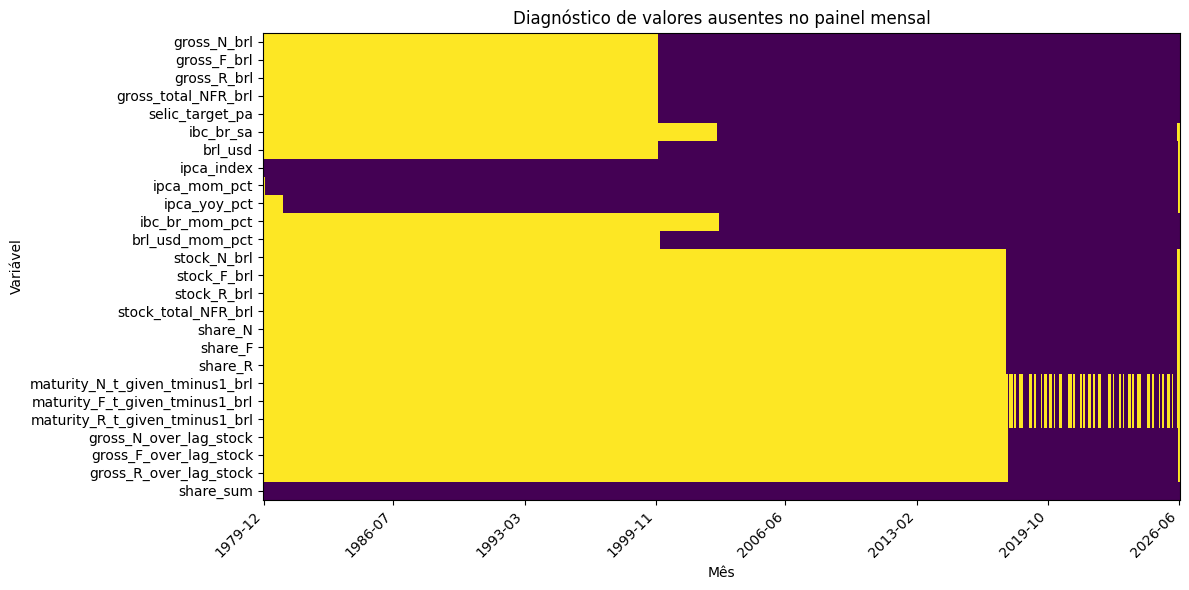

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/diagnostico_missing_values.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/diagnostico_missing_values.pdf


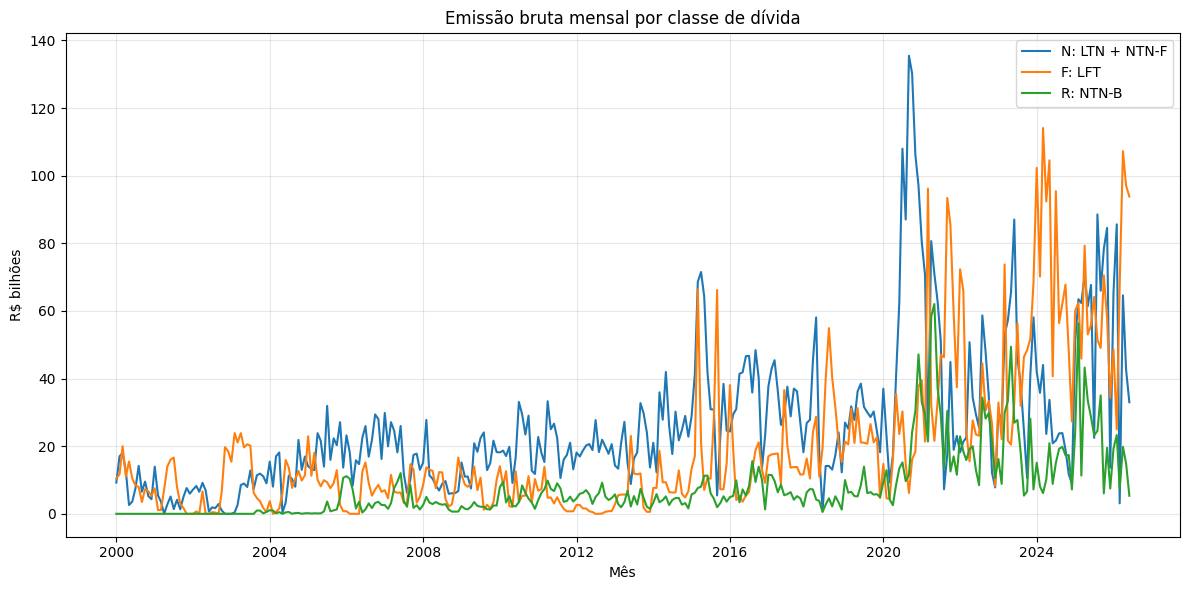

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_bruta_mensal_por_classe.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_bruta_mensal_por_classe.pdf


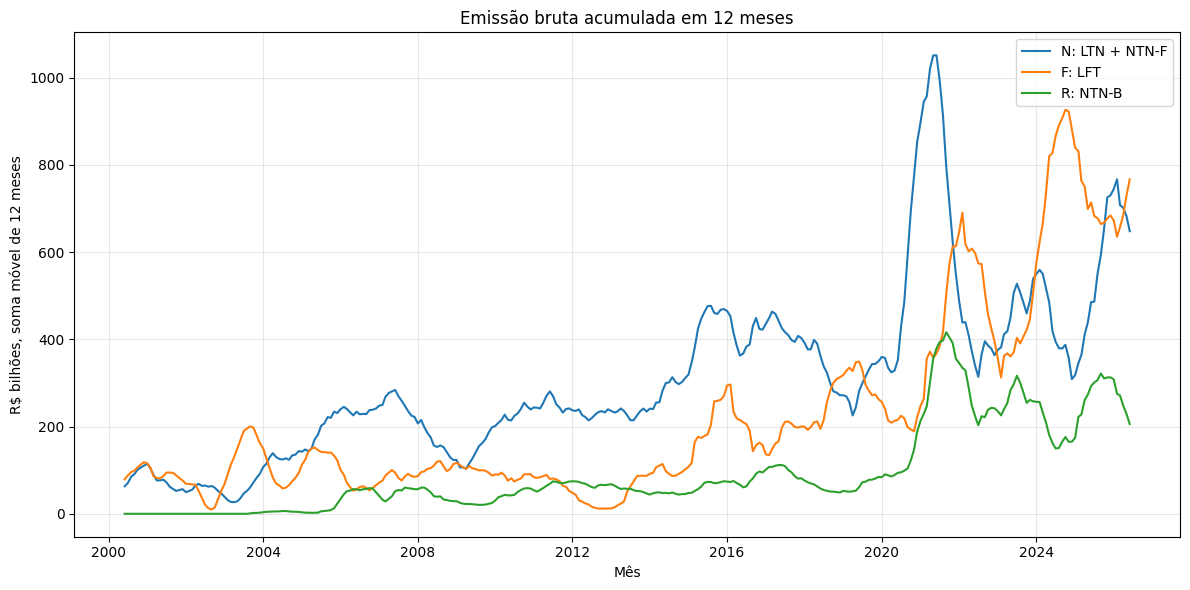

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_bruta_12m_por_classe.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_bruta_12m_por_classe.pdf


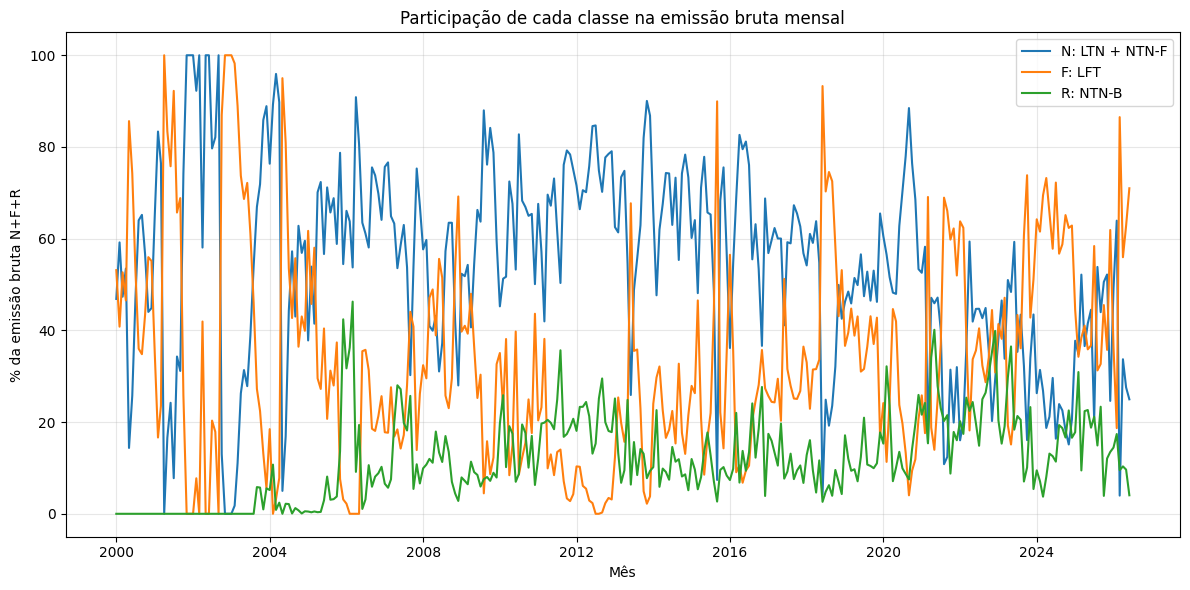

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/participacao_emissao_bruta_mensal.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/participacao_emissao_bruta_mensal.pdf


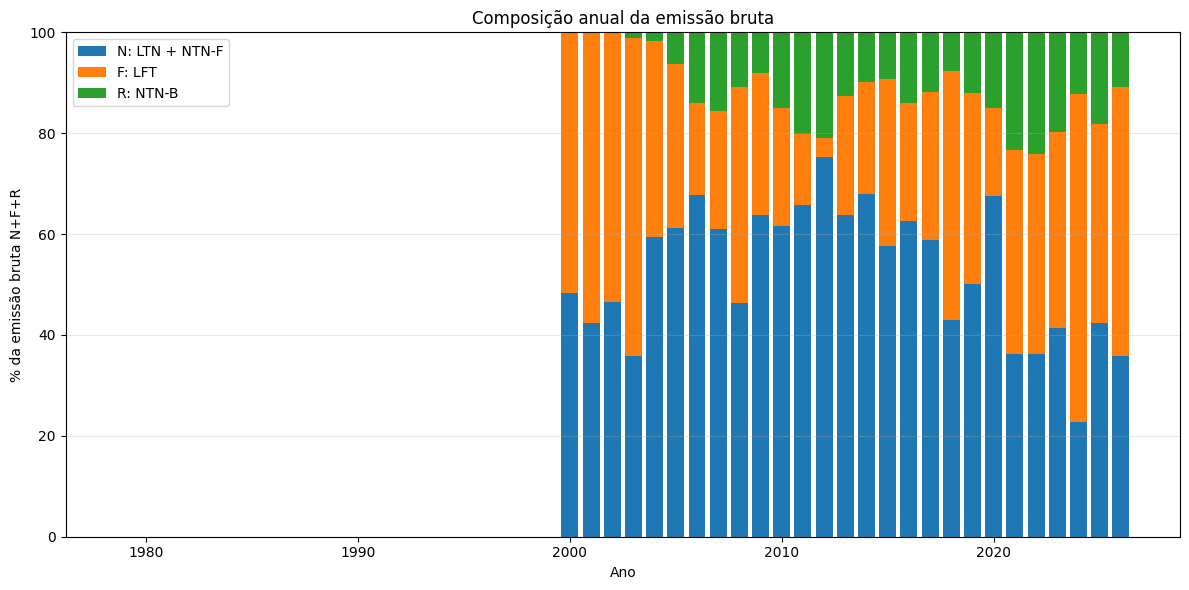

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/composicao_anual_emissao_bruta.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/composicao_anual_emissao_bruta.pdf


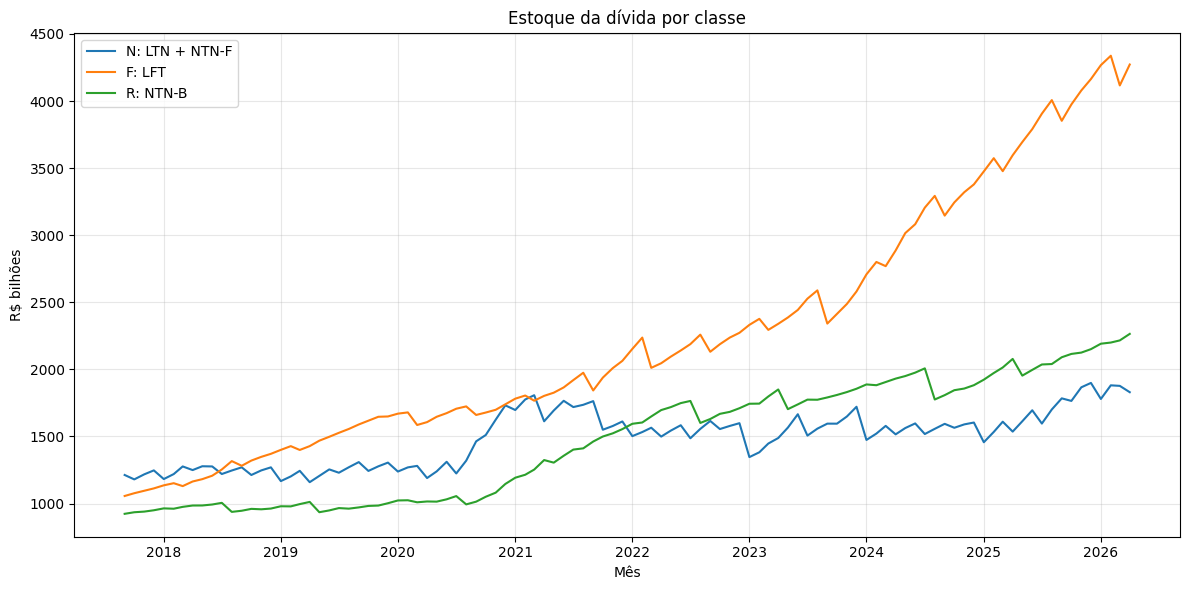

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/estoque_por_classe.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/estoque_por_classe.pdf


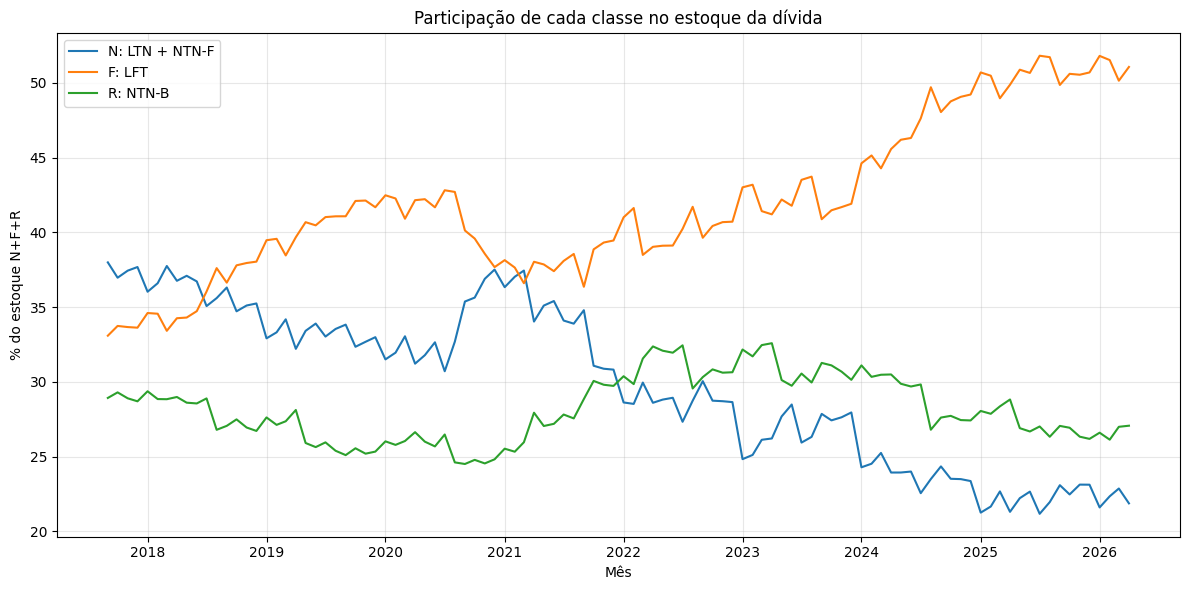

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/participacao_estoque_por_classe.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/participacao_estoque_por_classe.pdf


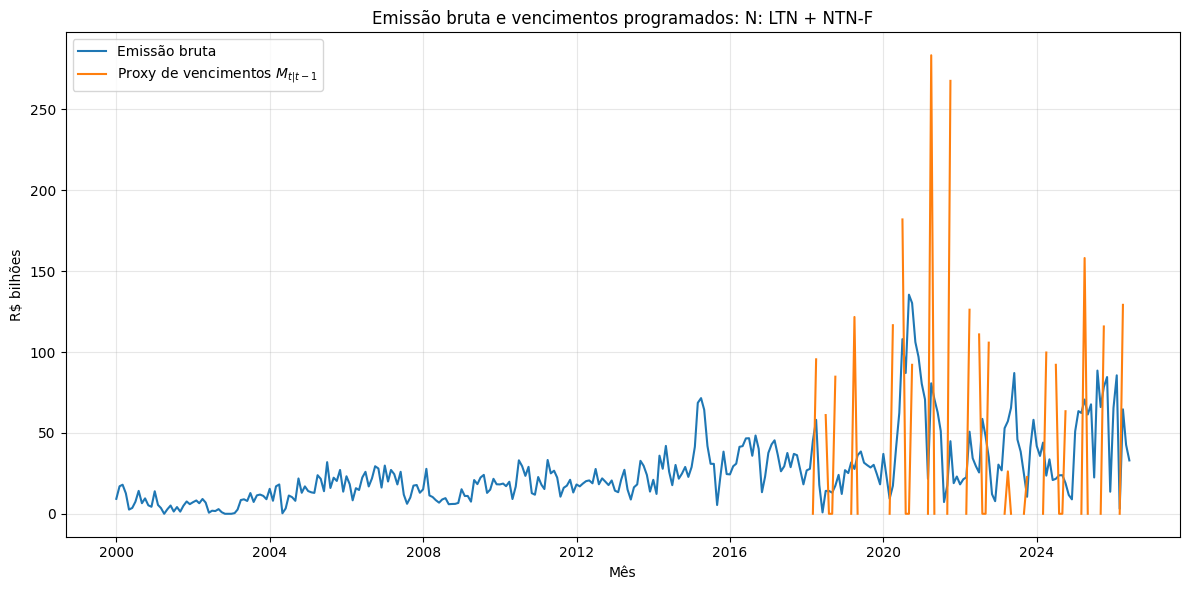

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_vs_vencimentos_N_LTN_NTNF.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_vs_vencimentos_N_LTN_NTNF.pdf


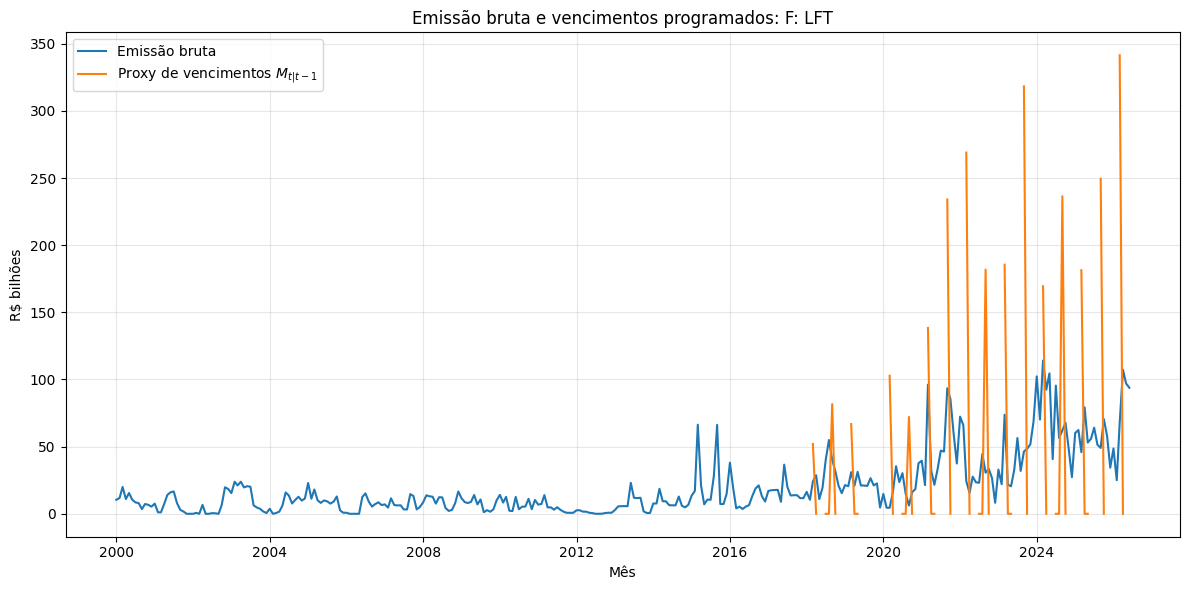

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_vs_vencimentos_F_LFT.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_vs_vencimentos_F_LFT.pdf


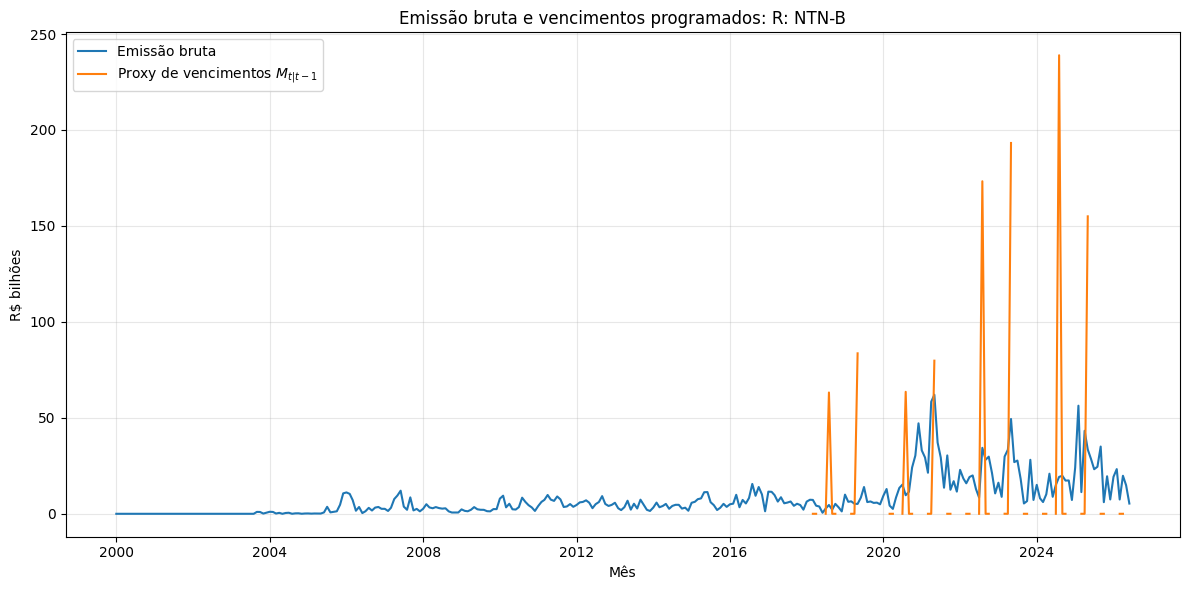

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_vs_vencimentos_R_NTNB.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_vs_vencimentos_R_NTNB.pdf


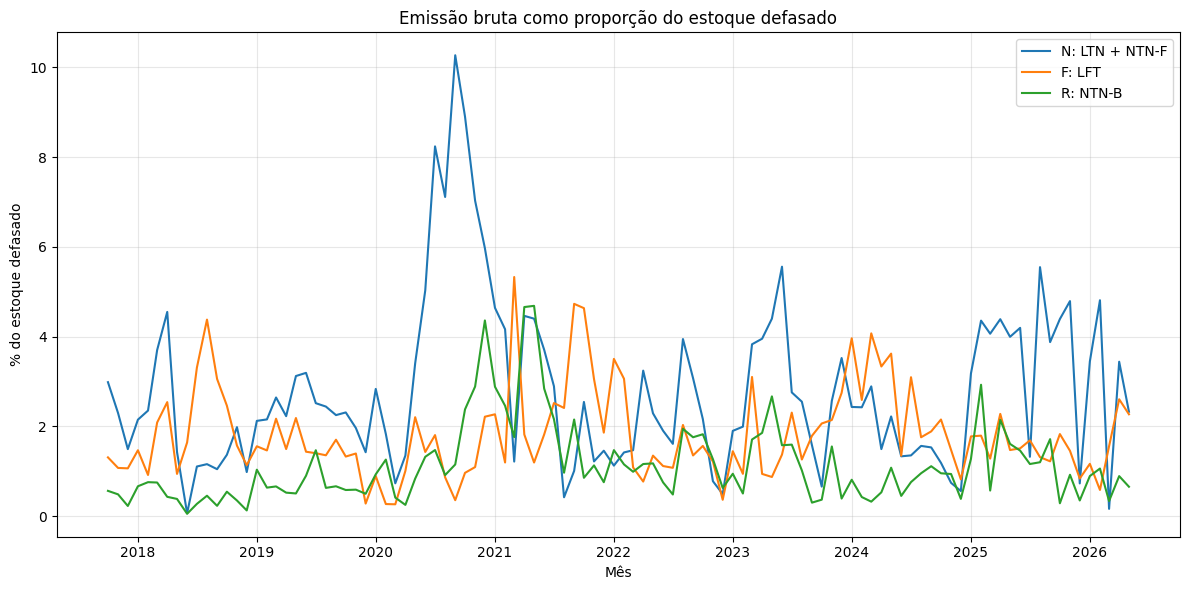

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_sobre_estoque_defasado.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/emissao_sobre_estoque_defasado.pdf


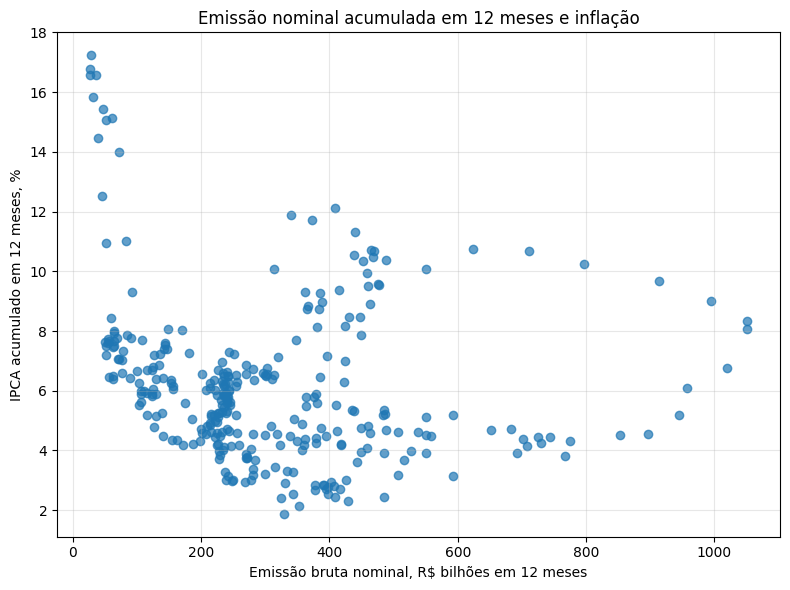

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/scatter_emissao_nominal_12m_ipca.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/scatter_emissao_nominal_12m_ipca.pdf


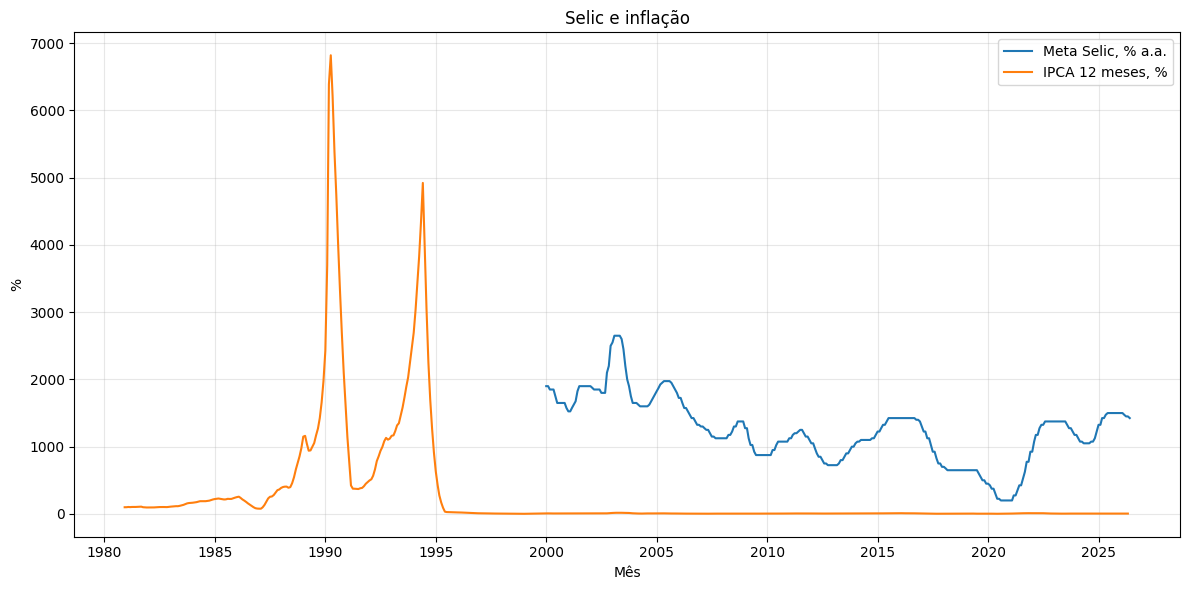

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/selic_e_ipca.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/selic_e_ipca.pdf


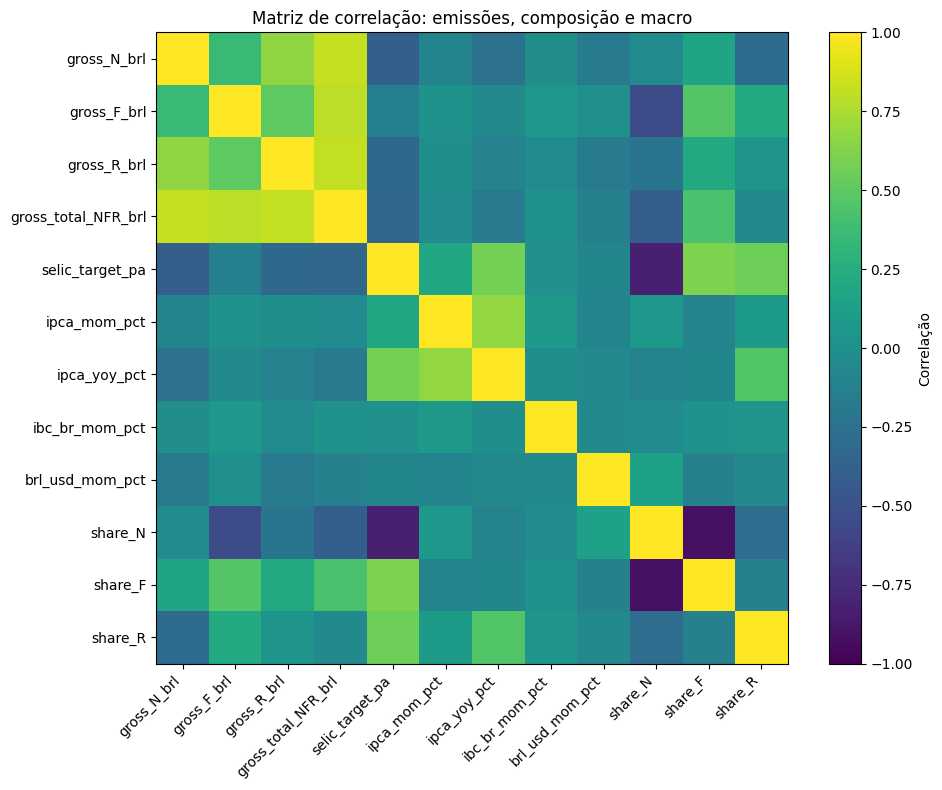

Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/correlacoes_emissoes_macro.png
Salvo em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/correlacoes_emissoes_macro.pdf


,gross_N_bi,gross_F_bi,gross_R_bi,gross_total_NFR_bi
year,,,,
2012,239.60,12.01,66.63,318.24
2013,234.42,86.93,46.66,368.00
2014,311.24,101.90,45.25,458.39
2015,469.43,269.67,74.64,813.73
2016,422.16,157.30,94.71,674.18
2017,403.03,200.25,81.58,684.85
2018,271.72,312.81,48.77,633.30
2019,349.58,262.92,84.48,696.98
2020,853.27,222.20,189.01,1264.47


Tabela anual salva em: /content/drive/MyDrive/UDESC/Projetos/FTPL/data/figures/annual_gross_issuance_summary_brl_billion.csv


In [18]:
# ================================================================
# Gráficos de diagnóstico e motivação para o projeto FTPL
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------
# 0. Preparação
# ------------------------------------------------

figures_dir = OUTPUT_DIR / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# Garante que a coluna de data está no formato correto
panel = panel.copy()
panel["month"] = pd.to_datetime(panel["month"])
panel = panel.sort_values("month").reset_index(drop=True)

# Escala para bilhões de reais
BRL_BILLION = 1e9

gross_cols = {
    "N: LTN + NTN-F": "gross_N_brl",
    "F: LFT": "gross_F_brl",
    "R: NTN-B": "gross_R_brl",
}

stock_cols = {
    "N: LTN + NTN-F": "stock_N_brl",
    "F: LFT": "stock_F_brl",
    "R: NTN-B": "stock_R_brl",
}

share_cols = {
    "N: LTN + NTN-F": "share_N",
    "F: LFT": "share_F",
    "R: NTN-B": "share_R",
}

maturity_cols = {
    "N: LTN + NTN-F": "maturity_N_t_given_tminus1_brl",
    "F: LFT": "maturity_F_t_given_tminus1_brl",
    "R: NTN-B": "maturity_R_t_given_tminus1_brl",
}


def save_current_figure(filename):
    """
    Salva a figura atual em PNG e PDF.
    """
    png_path = figures_dir / f"{filename}.png"
    pdf_path = figures_dir / f"{filename}.pdf"
    plt.tight_layout()
    plt.savefig(png_path, dpi=300, bbox_inches="tight")
    plt.savefig(pdf_path, bbox_inches="tight")
    plt.show()
    print(f"Salvo em: {png_path}")
    print(f"Salvo em: {pdf_path}")


def available(cols_dict):
    """
    Mantém apenas colunas que existem no painel.
    """
    return {label: col for label, col in cols_dict.items() if col in panel.columns}


# ------------------------------------------------
# 1. Diagnóstico: cobertura temporal e valores ausentes
# ------------------------------------------------

missing = (
    panel
    .set_index("month")
    .isna()
    .astype(int)
)

plt.figure(figsize=(12, 6))
plt.imshow(missing.T, aspect="auto", interpolation="nearest")
plt.yticks(range(len(missing.columns)), missing.columns)
plt.xticks(
    ticks=np.linspace(0, len(missing.index) - 1, 8).astype(int),
    labels=[
        missing.index[i].strftime("%Y-%m")
        for i in np.linspace(0, len(missing.index) - 1, 8).astype(int)
    ],
    rotation=45,
    ha="right",
)
plt.title("Diagnóstico de valores ausentes no painel mensal")
plt.xlabel("Mês")
plt.ylabel("Variável")
save_current_figure("diagnostico_missing_values")


# ------------------------------------------------
# 2. Emissão bruta mensal por instrumento
# ------------------------------------------------

cols = available(gross_cols)

plt.figure(figsize=(12, 6))
for label, col in cols.items():
    plt.plot(panel["month"], panel[col] / BRL_BILLION, label=label)

plt.title("Emissão bruta mensal por classe de dívida")
plt.xlabel("Mês")
plt.ylabel("R$ bilhões")
plt.legend()
plt.grid(True, alpha=0.3)
save_current_figure("emissao_bruta_mensal_por_classe")


# ------------------------------------------------
# 3. Emissão bruta acumulada em 12 meses
# ------------------------------------------------

plt.figure(figsize=(12, 6))
for label, col in cols.items():
    rolling_col = panel[col].rolling(12, min_periods=6).sum()
    plt.plot(panel["month"], rolling_col / BRL_BILLION, label=label)

plt.title("Emissão bruta acumulada em 12 meses")
plt.xlabel("Mês")
plt.ylabel("R$ bilhões, soma móvel de 12 meses")
plt.legend()
plt.grid(True, alpha=0.3)
save_current_figure("emissao_bruta_12m_por_classe")


# ------------------------------------------------
# 4. Participação de cada classe na emissão bruta total
# ------------------------------------------------

gross_existing = list(cols.values())

if gross_existing:
    gross_total = panel[gross_existing].sum(axis=1).replace(0, np.nan)

    plt.figure(figsize=(12, 6))
    for label, col in cols.items():
        share = panel[col] / gross_total
        plt.plot(panel["month"], 100 * share, label=label)

    plt.title("Participação de cada classe na emissão bruta mensal")
    plt.xlabel("Mês")
    plt.ylabel("% da emissão bruta N+F+R")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_current_figure("participacao_emissao_bruta_mensal")


# ------------------------------------------------
# 5. Composição anual da emissão bruta
# ------------------------------------------------

annual = panel.copy()
annual["year"] = annual["month"].dt.year

annual_gross = (
    annual
    .groupby("year")[gross_existing]
    .sum()
)

if not annual_gross.empty:
    annual_shares = annual_gross.div(
        annual_gross.sum(axis=1).replace(0, np.nan),
        axis=0
    )

    plt.figure(figsize=(12, 6))
    bottom = np.zeros(len(annual_shares))

    for label, col in cols.items():
        values = 100 * annual_shares[col].fillna(0).values
        plt.bar(annual_shares.index, values, bottom=bottom, label=label)
        bottom += values

    plt.title("Composição anual da emissão bruta")
    plt.xlabel("Ano")
    plt.ylabel("% da emissão bruta N+F+R")
    plt.legend()
    plt.grid(True, axis="y", alpha=0.3)
    save_current_figure("composicao_anual_emissao_bruta")


# ------------------------------------------------
# 6. Estoque por classe de dívida
# ------------------------------------------------

stock_existing = available(stock_cols)

if stock_existing:
    plt.figure(figsize=(12, 6))
    for label, col in stock_existing.items():
        plt.plot(panel["month"], panel[col] / BRL_BILLION, label=label)

    plt.title("Estoque da dívida por classe")
    plt.xlabel("Mês")
    plt.ylabel("R$ bilhões")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_current_figure("estoque_por_classe")


# ------------------------------------------------
# 7. Participação no estoque da dívida
# ------------------------------------------------

share_existing = available(share_cols)

if share_existing:
    plt.figure(figsize=(12, 6))
    for label, col in share_existing.items():
        plt.plot(panel["month"], 100 * panel[col], label=label)

    plt.title("Participação de cada classe no estoque da dívida")
    plt.xlabel("Mês")
    plt.ylabel("% do estoque N+F+R")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_current_figure("participacao_estoque_por_classe")


# ------------------------------------------------
# 8. Emissão bruta versus proxy de vencimentos programados
# ------------------------------------------------

maturity_existing = available(maturity_cols)

for label in cols.keys():
    gross_col = gross_cols.get(label)
    maturity_col = maturity_cols.get(label)

    if gross_col in panel.columns and maturity_col in panel.columns:
        plt.figure(figsize=(12, 6))
        plt.plot(
            panel["month"],
            panel[gross_col] / BRL_BILLION,
            label="Emissão bruta"
        )
        plt.plot(
            panel["month"],
            panel[maturity_col] / BRL_BILLION,
            label=r"Proxy de vencimentos $M_{t|t-1}$"
        )
        plt.title(f"Emissão bruta e vencimentos programados: {label}")
        plt.xlabel("Mês")
        plt.ylabel("R$ bilhões")
        plt.legend()
        plt.grid(True, alpha=0.3)

        safe_label = (
            label.replace(": ", "_")
            .replace(" + ", "_")
            .replace("-", "")
            .replace(" ", "_")
        )
        save_current_figure(f"emissao_vs_vencimentos_{safe_label}")


# ------------------------------------------------
# 9. Razão emissão bruta / estoque defasado
# ------------------------------------------------

over_lag_stock_cols = {
    "N: LTN + NTN-F": "gross_N_over_lag_stock",
    "F: LFT": "gross_F_over_lag_stock",
    "R: NTN-B": "gross_R_over_lag_stock",
}

over_existing = available(over_lag_stock_cols)

if over_existing:
    plt.figure(figsize=(12, 6))
    for label, col in over_existing.items():
        plt.plot(panel["month"], 100 * panel[col], label=label)

    plt.title("Emissão bruta como proporção do estoque defasado")
    plt.xlabel("Mês")
    plt.ylabel("% do estoque defasado")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_current_figure("emissao_sobre_estoque_defasado")


# ------------------------------------------------
# 10. Relação entre emissão nominal e inflação
#     Diagnóstico visual, sem interpretação causal
# ------------------------------------------------

if "gross_N_brl" in panel.columns and "ipca_yoy_pct" in panel.columns:
    plot_df = panel[["gross_N_brl", "ipca_yoy_pct"]].dropna().copy()
    plot_df["gross_N_12m_brl"] = (
        panel["gross_N_brl"]
        .rolling(12, min_periods=6)
        .sum()
    )
    plot_df = panel[["month", "gross_N_brl", "ipca_yoy_pct"]].copy()
    plot_df["gross_N_12m_brl"] = (
        plot_df["gross_N_brl"]
        .rolling(12, min_periods=6)
        .sum()
    )
    plot_df = plot_df.dropna(subset=["gross_N_12m_brl", "ipca_yoy_pct"])

    plt.figure(figsize=(8, 6))
    plt.scatter(
        plot_df["gross_N_12m_brl"] / BRL_BILLION,
        plot_df["ipca_yoy_pct"],
        alpha=0.7
    )
    plt.title("Emissão nominal acumulada em 12 meses e inflação")
    plt.xlabel("Emissão bruta nominal, R$ bilhões em 12 meses")
    plt.ylabel("IPCA acumulado em 12 meses, %")
    plt.grid(True, alpha=0.3)
    save_current_figure("scatter_emissao_nominal_12m_ipca")


# ------------------------------------------------
# 11. Selic, inflação e composição: motivação macrofinanceira
# ------------------------------------------------

if {"selic_target_pa", "ipca_yoy_pct"}.issubset(panel.columns):
    plt.figure(figsize=(12, 6))
    plt.plot(panel["month"], panel["selic_target_pa"], label="Meta Selic, % a.a.")
    plt.plot(panel["month"], panel["ipca_yoy_pct"], label="IPCA 12 meses, %")
    plt.title("Selic e inflação")
    plt.xlabel("Mês")
    plt.ylabel("%")
    plt.legend()
    plt.grid(True, alpha=0.3)
    save_current_figure("selic_e_ipca")


# ------------------------------------------------
# 12. Correlações entre emissões brutas e variáveis macro
# ------------------------------------------------

candidate_corr_cols = [
    "gross_N_brl",
    "gross_F_brl",
    "gross_R_brl",
    "gross_total_NFR_brl",
    "selic_target_pa",
    "ipca_mom_pct",
    "ipca_yoy_pct",
    "ibc_br_mom_pct",
    "brl_usd_mom_pct",
    "share_N",
    "share_F",
    "share_R",
]

corr_cols = [c for c in candidate_corr_cols if c in panel.columns]

if len(corr_cols) >= 2:
    corr_df = panel[corr_cols].copy()

    # Reescala emissões para bilhões apenas para facilitar inspeção;
    # correlações não mudam com reescala positiva.
    for c in corr_df.columns:
        if c.endswith("_brl"):
            corr_df[c] = corr_df[c] / BRL_BILLION

    corr = corr_df.corr()

    plt.figure(figsize=(10, 8))
    plt.imshow(corr, vmin=-1, vmax=1)
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.colorbar(label="Correlação")
    plt.title("Matriz de correlação: emissões, composição e macro")
    save_current_figure("correlacoes_emissoes_macro")


# ------------------------------------------------
# 13. Tabela-resumo anual da emissão
# ------------------------------------------------

annual_summary = annual_gross.copy()

if not annual_summary.empty:
    annual_summary["gross_total_NFR_brl"] = annual_summary.sum(axis=1)

    for col in annual_summary.columns:
        annual_summary[col.replace("_brl", "_bi")] = (
            annual_summary[col] / BRL_BILLION
        )

    annual_summary_out = annual_summary[
        [c for c in annual_summary.columns if c.endswith("_bi")]
    ].round(2)

    display(annual_summary_out.tail(15))

    annual_summary_out.to_csv(
        figures_dir / "annual_gross_issuance_summary_brl_billion.csv"
    )

    print(
        "Tabela anual salva em:",
        figures_dir / "annual_gross_issuance_summary_brl_billion.csv"
    )

## Normalização de emissões e vencimentos por PIB

Nesta etapa, normalizamos as séries de emissão bruta e de vencimentos programados pelo PIB nominal defasado. O objetivo é colocar os fluxos de dívida em uma escala macroeconômica comum, permitindo comparar a magnitude das emissões entre instrumentos e ao longo do tempo.

A normalização principal utiliza o PIB nominal acumulado em 12 meses, defasado em um mês:

$
\frac{G_t^j}{PIB_{t-1}^{12m}},
\qquad
\frac{M_{t\mid t-1}^j}{PIB_{t-1}^{12m}},
$

onde \(G_t^j\) é a emissão bruta da classe \(j\) no mês \(t\), e \(M_{t\mid t-1}^j\) é a proxy de vencimentos programados da mesma classe, construída com informação disponível em \(t-1\).

O uso do PIB defasado evita incorporar informação contemporânea do mês \(t\) na escala dos regressores. Além disso, o PIB acumulado em 12 meses é preferível ao PIB mensal isolado porque fornece uma medida mais estável da escala nominal da economia.

As variáveis criadas têm duas versões:

- em proporção do PIB, por exemplo `g_N_pib`;
- em percentual do PIB, por exemplo `g_N_pib_pct`.

A interpretação é direta: se `g_N_pib_pct = 0.4`, a emissão bruta de dívida nominal prefixada no mês correspondeu a 0,4% do PIB nominal acumulado em 12 meses, defasado em um mês.

Essa normalização será usada na primeira etapa da construção dos choques de emissão:

$
g_t^j
=
\alpha^j
+
\delta_0^j m_{t\mid t-1}^j
+
\delta_1^j m_{t+1\mid t-1}^j
+
\Lambda^{j\prime}Z_{t-1}
+
\mu_{m(t)}^j
+
u_t^j.
$

Na especificação baseline, tanto a emissão quanto os vencimentos entram normalizados pelo mesmo denominador, garantindo que os coeficientes da equação de previsão tenham interpretação consistente.

In [19]:
# ================================================================
# Normalização de emissões e vencimentos por PIB defasado
# ================================================================

from datetime import date
import pandas as pd
import numpy as np

# ------------------------------------------------
# 1. Baixar PIB mensal nominal do SGS/BCB
# ------------------------------------------------
# Série SGS 4380: PIB mensal - valores correntes (R$ milhões)
# A função fetch_bcb_sgs já foi definida anteriormente no notebook.

pib_monthly_raw = fetch_bcb_sgs(
    session=session,
    code=4380,
    name="pib_monthly_brl_million",
    start=date(2000, 1, 1),
)

pib_monthly = pib_monthly_raw.copy()
pib_monthly["month"] = (
    pd.to_datetime(pib_monthly["date"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

# Converte de R$ milhões para R$
pib_monthly["pib_monthly_brl"] = (
    pib_monthly["pib_monthly_brl_million"] * 1_000_000
)

pib_monthly = (
    pib_monthly[["month", "pib_monthly_brl"]]
    .dropna()
    .drop_duplicates(subset="month", keep="last")
    .sort_values("month")
    .reset_index(drop=True)
)

# ------------------------------------------------
# 2. Construir PIB acumulado em 12 meses
# ------------------------------------------------
# Para normalizar fluxos mensais de dívida, é mais usual usar
# o PIB nominal acumulado em 12 meses, pois o denominador fica
# na escala anual da economia.

pib_monthly["pib_12m_brl"] = (
    pib_monthly["pib_monthly_brl"]
    .rolling(window=12, min_periods=12)
    .sum()
)

# PIB defasado: informação disponível antes da emissão do mês t
pib_monthly["pib_12m_lag1_brl"] = (
    pib_monthly["pib_12m_brl"]
    .shift(1)
)

# ------------------------------------------------
# 3. Juntar PIB ao painel mensal
# ------------------------------------------------

panel = panel.copy()
panel["month"] = (
    pd.to_datetime(panel["month"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

panel = panel.merge(
    pib_monthly[["month", "pib_monthly_brl", "pib_12m_brl", "pib_12m_lag1_brl"]],
    on="month",
    how="left",
)

# ------------------------------------------------
# 4. Normalizar emissão bruta por PIB defasado
# ------------------------------------------------

issuance_cols = {
    "N": "gross_N_brl",
    "F": "gross_F_brl",
    "R": "gross_R_brl",
    "total_NFR": "gross_total_NFR_brl",
}

for suffix, col in issuance_cols.items():
    if col in panel.columns:
        panel[f"{col}_over_pib_lag1"] = (
            panel[col] / panel["pib_12m_lag1_brl"]
        )
        panel[f"{col}_over_pib_lag1_pct"] = (
            100 * panel[f"{col}_over_pib_lag1"]
        )

# ------------------------------------------------
# 5. Normalizar vencimentos por PIB defasado
# ------------------------------------------------

maturity_cols = {
    "N": "maturity_N_t_given_tminus1_brl",
    "F": "maturity_F_t_given_tminus1_brl",
    "R": "maturity_R_t_given_tminus1_brl",
    "total_NFR": "maturity_total_NFR_t_given_tminus1_brl",
}

for suffix, col in maturity_cols.items():
    if col in panel.columns:
        panel[f"{col}_over_pib_lag1"] = (
            panel[col] / panel["pib_12m_lag1_brl"]
        )
        panel[f"{col}_over_pib_lag1_pct"] = (
            100 * panel[f"{col}_over_pib_lag1"]
        )

# ------------------------------------------------
# 6. Criar nomes mais curtos para uso econométrico
# ------------------------------------------------

rename_short = {
    "gross_N_brl_over_pib_lag1": "g_N_pib",
    "gross_F_brl_over_pib_lag1": "g_F_pib",
    "gross_R_brl_over_pib_lag1": "g_R_pib",
    "gross_total_NFR_brl_over_pib_lag1": "g_total_NFR_pib",

    "gross_N_brl_over_pib_lag1_pct": "g_N_pib_pct",
    "gross_F_brl_over_pib_lag1_pct": "g_F_pib_pct",
    "gross_R_brl_over_pib_lag1_pct": "g_R_pib_pct",
    "gross_total_NFR_brl_over_pib_lag1_pct": "g_total_NFR_pib_pct",

    "maturity_N_t_given_tminus1_brl_over_pib_lag1": "m_N_pib",
    "maturity_F_t_given_tminus1_brl_over_pib_lag1": "m_F_pib",
    "maturity_R_t_given_tminus1_brl_over_pib_lag1": "m_R_pib",
    "maturity_total_NFR_t_given_tminus1_brl_over_pib_lag1": "m_total_NFR_pib",

    "maturity_N_t_given_tminus1_brl_over_pib_lag1_pct": "m_N_pib_pct",
    "maturity_F_t_given_tminus1_brl_over_pib_lag1_pct": "m_F_pib_pct",
    "maturity_R_t_given_tminus1_brl_over_pib_lag1_pct": "m_R_pib_pct",
    "maturity_total_NFR_t_given_tminus1_brl_over_pib_lag1_pct": "m_total_NFR_pib_pct",
}

for old, new in rename_short.items():
    if old in panel.columns:
        panel[new] = panel[old]

# ------------------------------------------------
# 7. Salvar painel atualizado
# ------------------------------------------------

normalized_path = OUTPUT_DIR / "clean" / "ftpl_monthly_panel_with_pib_normalization.csv"

panel.to_csv(
    normalized_path,
    index=False,
    encoding="utf-8",
)

print("Painel com normalização por PIB salvo em:")
print(normalized_path)

# ------------------------------------------------
# 8. Diagnóstico rápido
# ------------------------------------------------

diagnostic_cols = [
    "month",
    "pib_12m_lag1_brl",
    "g_N_pib_pct",
    "g_F_pib_pct",
    "g_R_pib_pct",
    "m_N_pib_pct",
    "m_F_pib_pct",
    "m_R_pib_pct",
]

diagnostic_cols = [c for c in diagnostic_cols if c in panel.columns]

display(panel[diagnostic_cols].dropna().head())
display(panel[diagnostic_cols].dropna().tail())

print("Resumo das emissões brutas em % do PIB defasado:")
display(
    panel[
        [c for c in ["g_N_pib_pct", "g_F_pib_pct", "g_R_pib_pct"] if c in panel.columns]
    ].describe().T
)

print("Resumo dos vencimentos em % do PIB defasado:")
display(
    panel[
        [c for c in ["m_N_pib_pct", "m_F_pib_pct", "m_R_pib_pct"] if c in panel.columns]
    ].describe().T
)

Painel com normalização por PIB salvo em:
/content/drive/MyDrive/UDESC/Projetos/FTPL/data/clean/ftpl_monthly_panel_with_pib_normalization.csv


,month,pib_12m_lag1_brl,g_N_pib_pct,g_F_pib_pct,g_R_pib_pct,m_N_pib_pct,m_F_pib_pct,m_R_pib_pct
454,2017-10-01,6.497847e+13,0.055742,0.021319,0.008041,0.121928,0.000000,0.0
457,2018-01-01,6.585479e+13,0.040741,0.024840,0.009637,0.127024,0.000000,0.0
459,2018-03-01,6.653616e+13,0.067848,0.036138,0.010860,0.000000,0.078058,0.0
460,2018-04-01,6.681889e+13,0.086930,0.042986,0.006318,0.142946,0.000000,0.0
463,2018-07-01,6.785258e+13,0.020849,0.058908,0.004038,0.089958,0.000000,0.0


,month,pib_12m_lag1_brl,g_N_pib_pct,g_F_pib_pct,g_R_pib_pct,m_N_pib_pct,m_F_pib_pct,m_R_pib_pct
549,2025-09-01,1.244277e+14,0.053031,0.039410,0.028161,0.000000,0.200361,0.0
550,2025-10-01,1.252450e+14,0.062568,0.056314,0.004833,0.092477,0.000000,0.0
553,2026-01-01,1.273857e+14,0.051396,0.038170,0.015120,0.138588,0.000000,0.0
555,2026-03-01,1.286419e+14,0.002414,0.052618,0.005791,0.000000,0.265380,0.0
556,2026-04-01,1.296482e+14,0.049832,0.082731,0.015286,0.099650,0.000000,0.0


Resumo das emissões brutas em % do PIB defasado:


,count,mean,std,min,25%,50%,75%,max
g_N_pib_pct,305.0,0.052062,0.030831,0.0,0.030694,0.047288,0.066498,0.181988
g_F_pib_pct,305.0,0.034730,0.031050,0.0,0.011806,0.027878,0.046391,0.159042
g_R_pib_pct,305.0,0.012136,0.011936,0.0,0.004833,0.009087,0.015814,0.076906


Resumo dos vencimentos em % do PIB defasado:


,count,mean,std,min,25%,50%,75%,max
m_N_pib_pct,59.0,0.083391,0.089464,0.0,0.0,0.089609,0.134444,0.358959
m_F_pib_pct,59.0,0.049398,0.089322,0.0,0.0,0.000000,0.086320,0.298401
m_R_pib_pct,59.0,0.018601,0.050192,0.0,0.0,0.000000,0.000000,0.209021


## 15. Próximos passos econométricos

Depois de construir o painel, os próximos passos são:

1. construir os fatores macrofinanceiros ou componentes principais;
2. estimar a equação de previsão da emissão:
   $
   g_t^j
   =
   \alpha^j
   +
   \delta_0^j m_{t\mid t-1}^j
   +
   \delta_1^j m_{t+1\mid t-1}^j
   +
   \Lambda^{j\prime}Z_{t-1}
   +
   u_t^j;
   $
3. extrair \(u_t^j\);
4. purgar revisões contemporâneas de expectativas fiscais;
5. estimar as local projections.
